# 04 · Проверка классификаторов JNU: неопределённость, ошибки и устойчивость

## tl;dr

Этот ноутбук проверяет **замороженные** модели из 03. Здесь не выбираются новые признаки, параметры, пороги или победители. Оценка: bootstrap по независимым patient-components, калибровка, ошибки, доступность входов, качество, округление и выпадение измерений. Отрицательный контроль использует только train. Префиксы 10/17/20 min не получают метку всей записи.

Независимый валидатор проверил **15 экспортированных моделей**: границы групп, все train-строки, медианы/IQR каждого fit, native CatBoost roundtrip, калибровочную группу, исследовательские пороги и ручную арифметику test. Предыдущие данные и результаты сохранены.

**Основной численный результат:** на расширенном 13-полевом профиле CatBoost: Macro-F1 **0.751** (95% CI **0.736–0.766**), recall abnormal **76.2%**, AP **0.856**. Сплайновая модель: F1 **0.751**; выбранная на train линейная: **0.749**. Парная разница CatBoost–сплайны не установила преимущество по F1. У CatBoost остаётся **527 пропущенных abnormal из 2219 записей** и 491 ложная тревога. Это числа записей, поэтому доли из них слегка отличаются от основных метрик с весами пациенток.

Все 15 финальных конфигураций выбрали single: усреднение пяти моделей не выполнило заранее заданный критерий. Округление изменило 0.27–1.21% ответов победителей; принудительное удаление всех представлений STV — 33.9–48.1% у использующих его профилей. NaN-поддержка не означает пригодности неполного бланка для клинического решения.

1000 bootstrap-выборок оценивают неопределённость при повторном наборе пациенток из этой когорты **для уже зафиксированных моделей**. Они не учитывают весь процесс переобучения/подбора и не доказывают перенос между странами/приборами. Изученные здесь численные возмущения не являются клинически валидированной моделью ошибок измерения.


## Context & Methods

### Key Assumptions

Независимая единица bootstrap — patient_component, а не запись. При повторном выборе компоненты её исходные patient-weights умножаются на кратность; веса нельзя пересчитать так, чтобы повторный выбор потерял смысл. AP и AUC учитывают совпадающие вероятности целыми группами порогов. Перекрытие CI не является полноценным тестом разницы; для CatBoost и spline приведены **парные** bootstrap-разницы на одних и тех же выборках.

Округление/отсутствие поля — заранее заданная численная чувствительность. Из двух единиц STV одновременно удаляются обе; иначе одна могла бы скрыто восстановить другую. При отсутствующем обязательном поле техническая политика должна отказывать или выбирать подтверждённый другой профиль; forced predictions в таблице не являются разрешением такого ввода в приложение.


In [3]:
from pathlib import Path
import sys,json,io,contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import confusion_matrix,precision_recall_curve,roc_curve
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'pyproject.toml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.training.jnu_report_experiment import OUT,EXPORT,metadata,inputs
from src.training.jnu_report_models import patient_weights
sns.set_theme(style='whitegrid',font_scale=1.02)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False})
pd.set_option('display.max_colwidth',100)
COLORS={'catboost':'#0072b2','spline_logit':'#d55e00','linear':'#009e73'}
def save_show(name):
    plt.gcf().savefig(OUT/name,dpi=140,bbox_inches='tight')
    plt.show()


## Data · замороженные артефакты и запуск оценки

Проверяется хеш `selection_frozen.json`. Все дополнительные результаты описательные; они не изменяют модель. Отрицательные контроли используют фиксированные конфигурации только на train: перестановку между равноразмерными группами и дополнительно одну случайную запись на компоненту с полной перестановкой fit-меток. Второй добавлен после обнаружения ограничения первого; ни один не использует test для обучения/выбора.


In [5]:
from src.training.jnu_report_assessment import run_assessment,check_tree_prefixes
intervals,paired=run_assessment()
frozen=json.loads((OUT/'selection_frozen.json').read_text())
if not (OUT/'tree_prefix_reuse_checks.csv').exists():check_tree_prefixes()
prefix=pd.read_csv(OUT/'tree_prefix_reuse_checks.csv')
assert len(prefix)==36 and prefix.max_probability_difference.max()<=1e-13
display(prefix.groupby('depth').agg(combinations=('train_rows','size'),max_difference=('max_probability_difference','max')))
from tools.validate_jnu_classifiers import validate
with (OUT/'notebook_validation.log').open('w') as log,contextlib.redirect_stdout(log):
    receipt=validate()
display(pd.DataFrame(receipt['checks']))


,combinations,max_difference
depth,,
3,12,0.0
4,12,0.0
6,12,0.0


,profile,family,mode,all_train_rows_retained,fitted_preprocessing_independently_checked,group_boundaries,export_roundtrip,calibration_only_calibration_patients,threshold_only_operating_patients,no_raw_signal_in_X,clinical_validation
0,minimal,catboost,single,True,True,True,True,True,True,True,False
1,minimal,spline_logit,single,True,True,True,True,True,True,True,False
2,minimal,linear,single,True,True,True,True,True,True,True,False
3,variability,catboost,single,True,True,True,True,True,True,True,False
4,variability,spline_logit,single,True,True,True,True,True,True,True,False
5,variability,linear,single,True,True,True,True,True,True,True,False
6,sonomed_fields,catboost,single,True,True,True,True,True,True,True,False
7,sonomed_fields,spline_logit,single,True,True,True,True,True,True,True,False
8,sonomed_fields,linear,single,True,True,True,True,True,True,True,False
9,mfmon_fields,catboost,single,True,True,True,True,True,True,True,False


## Results · интервалы качества и парные различия

95% percentile CI по 1000 кластерным повторным выборкам test. Выделены победители по train. Интервалы условны на зафиксированных моделях и данной популяции, не дают гарантии для другой клиники.


,profile,family,metric,estimate,ci_low,ci_high,repetitions,champion
9,minimal,spline_logit,macro_f1,0.6719,0.6551,0.6871,1000,True
10,minimal,spline_logit,recall,0.6702,0.6478,0.6914,1000,True
11,minimal,spline_logit,specificity,0.6760,0.6527,0.7000,1000,True
12,minimal,spline_logit,precision,0.7109,0.6910,0.7311,1000,True
14,minimal,spline_logit,ap,0.7818,0.7637,0.8015,1000,True
36,variability,spline_logit,macro_f1,0.7207,0.7053,0.7349,1000,True
37,variability,spline_logit,recall,0.7079,0.6868,0.7277,1000,True
38,variability,spline_logit,specificity,0.7373,0.7144,0.7590,1000,True
39,variability,spline_logit,precision,0.7621,0.7408,0.7810,1000,True
41,variability,spline_logit,ap,0.8234,0.8049,0.8403,1000,True


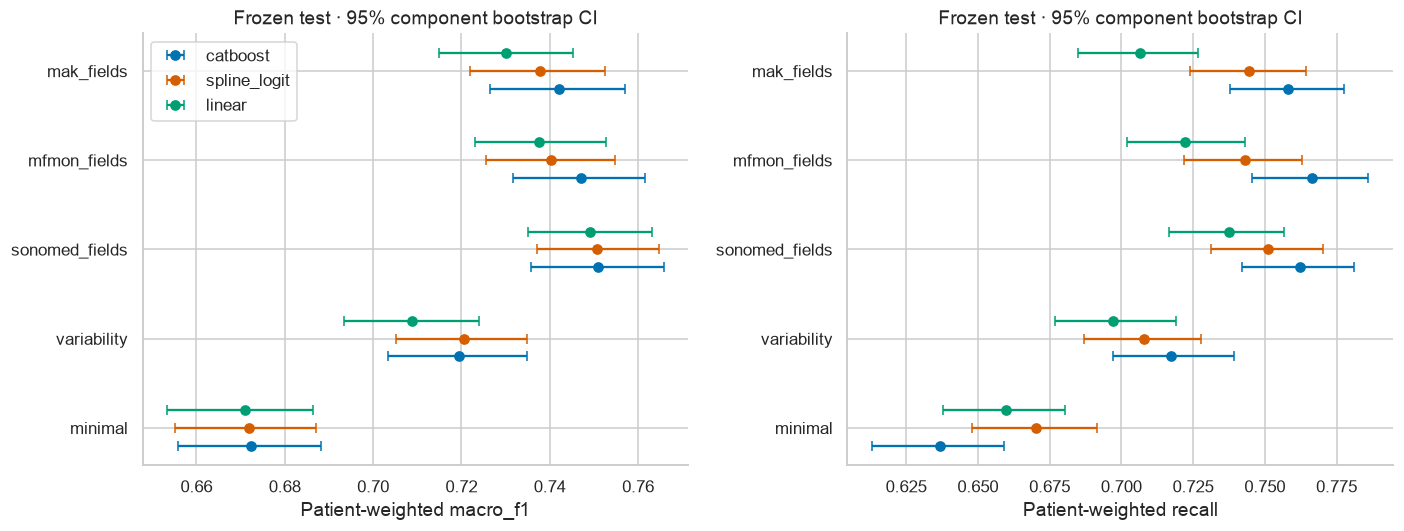

,profile,metric,comparison,mean_bootstrap_difference,ci_low,ci_high
0,minimal,macro_f1,CatBoost minus spline model,0.0006,-0.0073,0.0076
1,minimal,recall,CatBoost minus spline model,-0.0331,-0.0430,-0.0240
2,minimal,ap,CatBoost minus spline model,0.0050,-0.0006,0.0113
3,minimal,brier,CatBoost minus spline model,-0.0002,-0.0010,0.0005
4,variability,macro_f1,CatBoost minus spline model,-0.0011,-0.0084,0.0059
5,variability,recall,CatBoost minus spline model,0.0097,0.0005,0.0188
6,variability,ap,CatBoost minus spline model,0.0072,0.0014,0.0134
7,variability,brier,CatBoost minus spline model,-0.0010,-0.0024,0.0005
8,sonomed_fields,macro_f1,CatBoost minus spline model,-0.0002,-0.0081,0.0076
9,sonomed_fields,recall,CatBoost minus spline model,0.0110,0.0016,0.0204


In [7]:
display(intervals[intervals.champion.astype(bool)&intervals.metric.isin(['macro_f1','recall','specificity','precision','ap'])].round(4))
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,metric in zip(axes,['macro_f1','recall']):
    for j,family in enumerate(['catboost','spline_logit','linear']):
        d=intervals[(intervals.metric==metric)&(intervals.family==family)].set_index('profile').loc[list(frozen['champions'])]
        pos=np.arange(len(d))+(j-1)*.2
        ax.errorbar(d.estimate,pos,xerr=np.array([d.estimate-d.ci_low,d.ci_high-d.estimate]),fmt='o',capsize=3,color=COLORS[family],label=family)
    ax.set(yticks=range(len(frozen['champions'])),yticklabels=list(frozen['champions']),xlabel=f'Patient-weighted {metric}',title='Frozen test · 95% component bootstrap CI')
axes[0].legend();fig.tight_layout();save_show('06_bootstrap_intervals.png')
display(paired.round(4))


### Precision–Recall и калибровка

Кривая PR показывает цену повышения recall в ложных тревогах. AP рассчитывается как average precision. Горизонтальная линия — patient-weighted распространённость abnormal в test. Калибровка выполнена на другой группе пациенток; показанные test-точки не использованы для её изменения. Reliability-диаграмма не является индивидуальной гарантией.

Эффект sigmoid небольшой и не во всех test-метриках положительный; например, у расширенного CatBoost log loss 0.5077 → 0.5083. Отказ от калибровки после просмотра test был бы новым выбором по test, поэтому зафиксированный экспорт не изменён. Положительная монотонная sigmoid сохраняет ранжирование и AP.


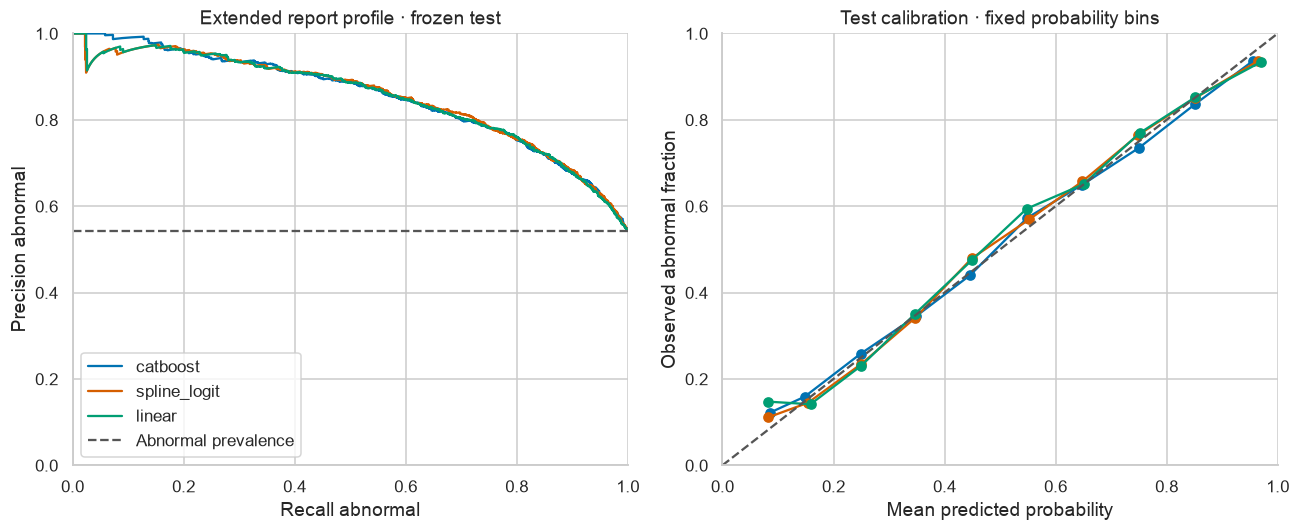

,profile,family,probabilities,brier,log_loss,ap
0,mak_fields,catboost,uncalibrated,0.1743,0.5219,0.8438
1,mak_fields,catboost,sigmoid,0.1744,0.5224,0.8438
2,mak_fields,linear,uncalibrated,0.1797,0.5397,0.8358
3,mak_fields,linear,sigmoid,0.1796,0.5399,0.8358
4,mak_fields,spline_logit,uncalibrated,0.1743,0.5261,0.8415
5,mak_fields,spline_logit,sigmoid,0.1743,0.5262,0.8415
6,mfmon_fields,catboost,uncalibrated,0.1718,0.5154,0.8488
7,mfmon_fields,catboost,sigmoid,0.1715,0.5152,0.8488
8,mfmon_fields,linear,uncalibrated,0.1746,0.5259,0.8443
9,mfmon_fields,linear,sigmoid,0.1745,0.5262,0.8443


In [9]:
pred=pd.read_parquet(OUT/'test_predictions.parquet')
bins=pd.read_csv(OUT/'test_reliability_bins.csv')
fig,axes=plt.subplots(1,2,figsize=(12,5))
for family in ['catboost','spline_logit','linear']:
    d=pred[(pred.profile=='sonomed_fields')&(pred.family==family)]
    w=patient_weights(d.patient_id);precision,recall,_=precision_recall_curve(d.figo_label,d.p,sample_weight=w)
    axes[0].plot(recall,precision,color=COLORS[family],label=family)
    z=bins[(bins.profile=='sonomed_fields')&(bins.family==family)]
    axes[1].plot(z.mean_probability,z.observed_fraction,'o-',color=COLORS[family],label=family)
axes[0].axhline(np.average(d.figo_label,weights=w),ls='--',color='#555555',label='Abnormal prevalence')
axes[0].set(xlabel='Recall abnormal',ylabel='Precision abnormal',xlim=(0,1),ylim=(0,1),title='Extended report profile · frozen test')
axes[1].plot([0,1],[0,1],'--',color='#555555');axes[1].set(xlabel='Mean predicted probability',ylabel='Observed abnormal fraction',xlim=(0,1),ylim=(0,1),title='Test calibration · fixed probability bins')
axes[0].legend();fig.tight_layout();save_show('07_pr_and_calibration.png')
display(pd.read_csv(OUT/'calibration_changes.csv').round(4))


### Округление и структурные пропуски

Baseline округляется до 1 BPM, вариабельность до 0.1 единицы; частоты событий не округляются как будто это счётчики. Удаление STV убирает все его представления. Метрики — **принудительные исследовательские предсказания** для анализа чувствительности; отдельно показан охват разрешённых обязательных полей.


,profile,family,scenario,core_coverage,complete_profile_coverage,patient_macro_f1,patient_recall,p95_probability_change,classification_flip_fraction
0,minimal,spline_logit,original,0.9969,0.9969,0.6719,0.6702,0.0000,0.0000
1,minimal,spline_logit,rounding,0.9969,0.9969,0.6724,0.6718,0.0053,0.0046
2,minimal,spline_logit,missing_baseline,0.0000,0.0000,0.3520,1.0000,0.3950,0.4937
3,variability,spline_logit,original,0.9969,0.9964,0.7207,0.7079,0.0000,0.0000
4,variability,spline_logit,rounding,0.9969,0.9964,0.7216,0.7080,0.0059,0.0034
5,variability,spline_logit,missing_STV,0.9969,0.0000,0.3739,0.9935,0.5851,0.4807
6,variability,spline_logit,missing_baseline,0.0000,0.0000,0.6890,0.8271,0.1394,0.1495
7,sonomed_fields,linear,original,0.9969,0.9964,0.7492,0.7375,0.0000,0.0000
8,sonomed_fields,linear,rounding,0.9969,0.9964,0.7513,0.7390,0.0262,0.0121
9,sonomed_fields,linear,missing_STV,0.9969,0.0000,0.5858,0.9460,0.4947,0.3386


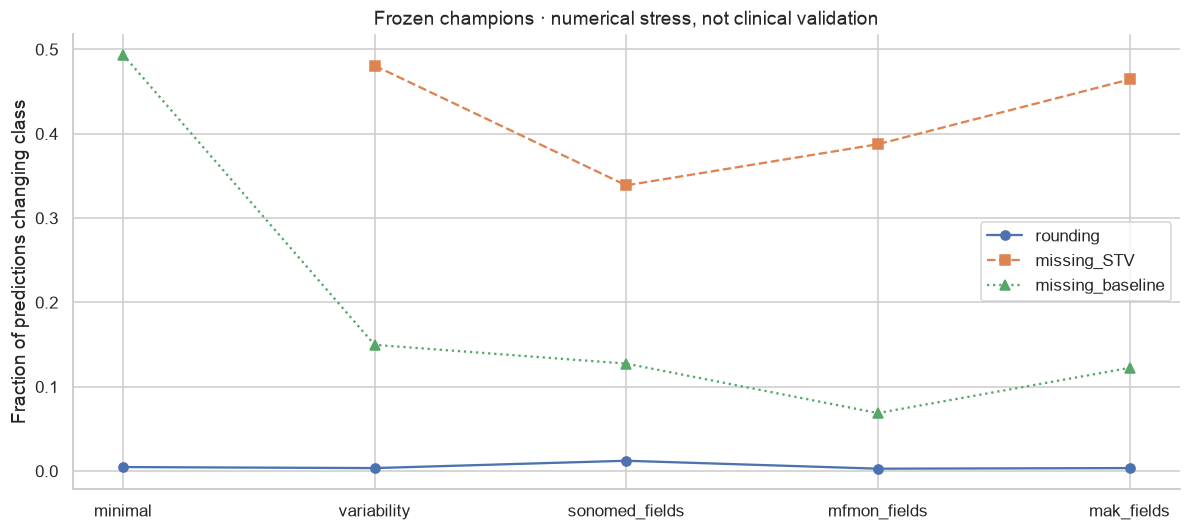

In [11]:
stress=pd.read_csv(OUT/'stress_tests.csv')
display(stress[['profile','family','scenario','core_coverage','complete_profile_coverage','patient_macro_f1','patient_recall','p95_probability_change','classification_flip_fraction']].round(4))
fig,ax=plt.subplots(figsize=(11,5))
for name,style in [('rounding','o-'),('missing_STV','s--'),('missing_baseline','^:')]:
    d=stress[stress.scenario==name].copy()
    ax.plot(d.profile,d.classification_flip_fraction,style,label=name)
ax.set(ylabel='Fraction of predictions changing class',title='Frozen champions · numerical stress, not clinical validation')
ax.legend();fig.tight_layout();save_show('08_measurement_stress.png')


### Что меняется на трудных записях

Quality-флаг из 02 не входит в X и не фильтровал обучение. Это описательная стратификация после заморозки. Для маленьких подгрупп метрики не публикуются; численность сохраняется. Patient weights пересчитываются внутри фактически оцениваемой подгруппы.

Для выбранной линейной модели расширенного профиля F1 на quality-pass 0.758, на quality-fail 0.627. Более высокий recall в трудной группе сопровождается другими распределениями классов и ошибками; он не означает лучшего клинического качества. В test 13 записей 12 пациенток не имеют всех core-измерений; они сохранены в общей оценке, отдельное качество такой малой группы не заявляется.


Самые уверенные ошибочные normal требуют экспертного разбора; метки не исправляются догадкой и модель не переобучается по test.


,profile,family,cohort,records,patients,abnormal_records,metrics_supported,patient_macro_f1,patient_recall,patient_specificity,patient_precision
0,minimal,spline_logit,full_cohort,4140,2520,2219,True,0.6719,0.6702,0.6760,0.7109
1,minimal,spline_logit,reference_quality_pass,3438,2207,1707,True,0.6959,0.7177,0.6744,0.6878
2,minimal,spline_logit,reference_quality_fail,702,657,512,True,0.5668,0.5220,0.7456,0.8497
3,minimal,spline_logit,core_missing,13,12,8,False,NaN,NaN,NaN,NaN
4,variability,spline_logit,full_cohort,4140,2520,2219,True,0.7207,0.7079,0.7373,0.7621
5,variability,spline_logit,reference_quality_pass,3438,2207,1707,True,0.7298,0.7037,0.7564,0.7427
6,variability,spline_logit,reference_quality_fail,702,657,512,True,0.6510,0.7262,0.6208,0.8407
7,variability,spline_logit,core_missing,13,12,8,False,NaN,NaN,NaN,NaN
8,sonomed_fields,linear,full_cohort,4140,2520,2219,True,0.7492,0.7375,0.7645,0.7883
9,sonomed_fields,linear,reference_quality_pass,3438,2207,1707,True,0.7580,0.6985,0.8194,0.7944


,record_id,figo_label,p,core_available,baseline_bpm,acc15_per_10min,dec15_per_10min,stv_ms,amplitude_bpm
2750,17643_1_210208000001,1.0,0.0342,True,74.7333,0.0000,0.0,6.1411,7.5000
2669,15026_1_210208000001,1.0,0.0657,True,124.3611,0.6667,0.0,10.9013,16.9655
2546,11608_1_210208000001,1.0,0.0690,True,130.9589,1.0000,0.0,7.1573,15.3000
2698,16071_1_210208000001,1.0,0.0898,True,130.5533,1.6667,0.0,9.1313,21.1333
3456,7982_1_210208000001,1.0,0.0968,True,143.9118,0.0000,0.0,7.6711,17.4333
3447,7461_1_210208000001,1.0,0.0995,True,136.2918,0.3333,0.0,6.3762,17.3846
2502,10177_1_210208000001,1.0,0.1019,True,126.6147,0.0000,0.0,5.5800,11.4000
2889,22041_1_210208000001,1.0,0.1090,True,131.7468,1.3333,0.0,7.0481,16.0000


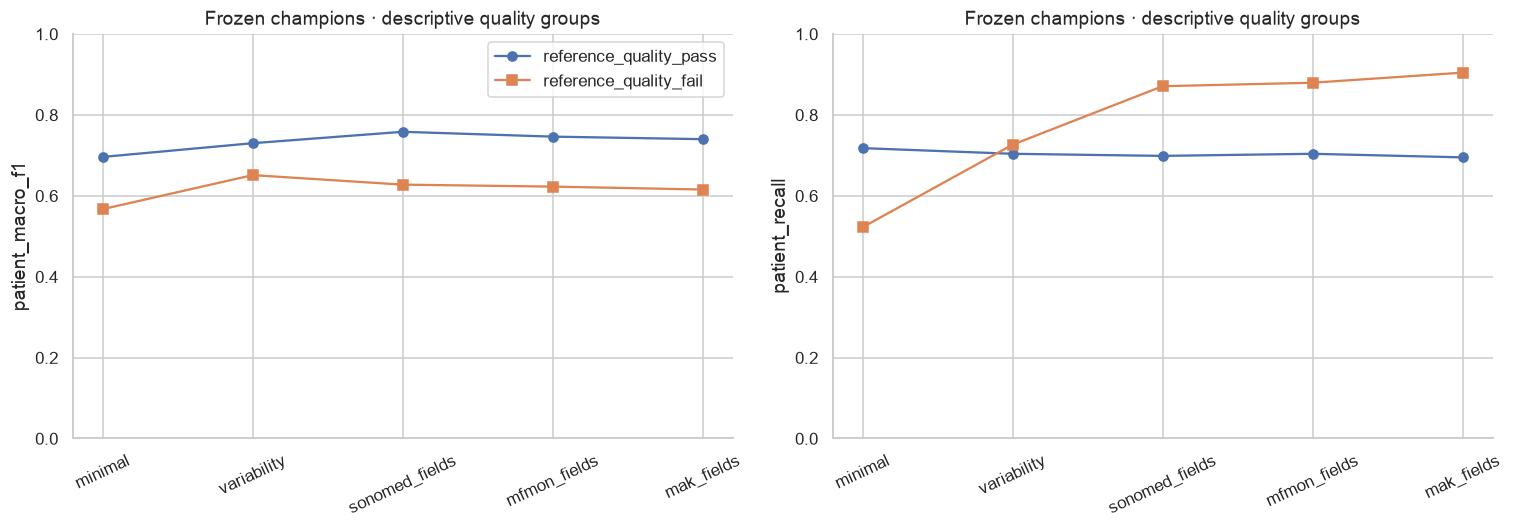

In [13]:
quality=pd.read_csv(OUT/'quality_subgroups.csv')
display(quality[['profile','family','cohort','records','patients','abnormal_records','metrics_supported','patient_macro_f1','patient_recall','patient_specificity','patient_precision']].round(4))
errors=pd.read_csv(OUT/'test_error_cases.csv')
hard=errors[(errors.profile=='sonomed_fields')&(errors.error_type=='false_negative')].sort_values('wrong_class_confidence',ascending=False).head(8)
display(hard[['record_id','figo_label','p','core_available','baseline_bpm','acc15_per_10min','dec15_per_10min','stv_ms','amplitude_bpm']].round(4))
print('Самые уверенные ошибочные normal требуют экспертного разбора; метки не исправляются догадкой и модель не переобучается по test.')
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,metric in zip(axes,['patient_macro_f1','patient_recall']):
    for name,marker in [('reference_quality_pass','o'),('reference_quality_fail','s')]:
        d=quality[quality.cohort==name]
        ax.plot(d.profile,d[metric],marker+'-',label=name)
    ax.set(ylabel=metric,ylim=(0,1),title='Frozen champions · descriptive quality groups')
    ax.tick_params(axis='x',labelrotation=25)
axes[0].legend();fig.tight_layout();save_show('09_quality_subgroups.png')


### Отрицательный контроль

Пять повторов каждого из двух контролей, фиксированные модели, только train. Перестановка между равноразмерными группами сохраняет часть связи «размер группы — метка»; её ROC-AUC может систематически отличаться от 0.5. После обнаружения такого эффекта добавлен второй диагностический контроль: ровно одна случайная запись на компоненту и полная перестановка её fit-меток. Выбор записи не использует target/сигнал и не считается первым по времени. Он не изменяет замороженные модели/test. Это **не формальные permutation p-values** и не доказательство отсутствия всех возможных утечек.

Средняя ROC-AUC первого контроля 0.530/0.534 (CatBoost/сплайны), второго 0.497/0.482. Пять повторов дают заметный разброс; это диагностическая проверка разрушения сигнала, а не оценка значимости результата. Близкие повторы сигналов за пределами найденных точных совпадений остаются отдельным риском источника.


,control,family,repetition,actual_changed_label_fraction,patient_roc_auc,patient_macro_f1
0,same_size_blocks,catboost,0,0.5008,0.5146,0.4534
1,same_size_blocks,spline_logit,0,0.5008,0.4935,0.4190
2,same_size_blocks,catboost,1,0.4965,0.5097,0.4388
3,same_size_blocks,spline_logit,1,0.4965,0.5329,0.4378
4,same_size_blocks,catboost,2,0.4937,0.5497,0.4459
5,same_size_blocks,spline_logit,2,0.4937,0.5321,0.4202
6,same_size_blocks,catboost,3,0.4899,0.5304,0.4469
7,same_size_blocks,spline_logit,3,0.4899,0.5472,0.4414
8,same_size_blocks,catboost,4,0.4801,0.5457,0.4635
9,same_size_blocks,spline_logit,4,0.4801,0.5657,0.4650


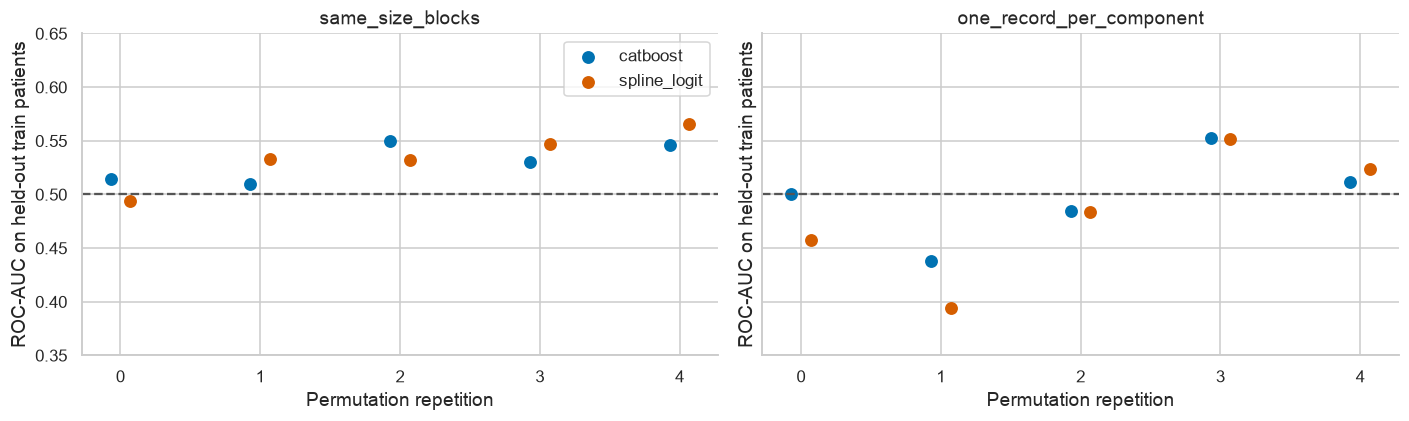

In [15]:
null=pd.read_csv(OUT/'train_only_negative_controls.csv')
display(null[['control','family','repetition','actual_changed_label_fraction','patient_roc_auc','patient_macro_f1']].round(4))
fig,axes=plt.subplots(1,2,figsize=(13,4),sharey=True)
for ax,control in zip(axes,['same_size_blocks','one_record_per_component']):
    for family,offset in [('catboost',-.07),('spline_logit',.07)]:
        d=null[(null.family==family)&(null.control==control)]
        ax.scatter(d.repetition+offset,d.patient_roc_auc,color=COLORS[family],label=family,s=55)
    ax.axhline(.5,color='#555555',ls='--');ax.set(xticks=range(5),xlabel='Permutation repetition',ylabel='ROC-AUC on held-out train patients',ylim=(.35,.65),title=control)
axes[0].legend();fig.tight_layout();save_show('10_negative_control.png')


### Короткая запись: только изменение выхода модели

Те же 128 train-записей из 02, часть уже встречалась fit моделей. Здесь **нет** оценки качества, новых независимых пациенток или размеченной FIGO короткого окна. Сравнение показывает, насколько меняется ответ модели при другой информации во времени. Оно не разрешает использовать модель на 17-min бланке.


,count,median,mean,max
prefix_min,,,,
10,128,0.0968,0.1382,0.6485
17,128,0.0668,0.1080,0.5648
20,128,0.0541,0.0881,0.5025
30,128,0.0000,0.0000,0.0000


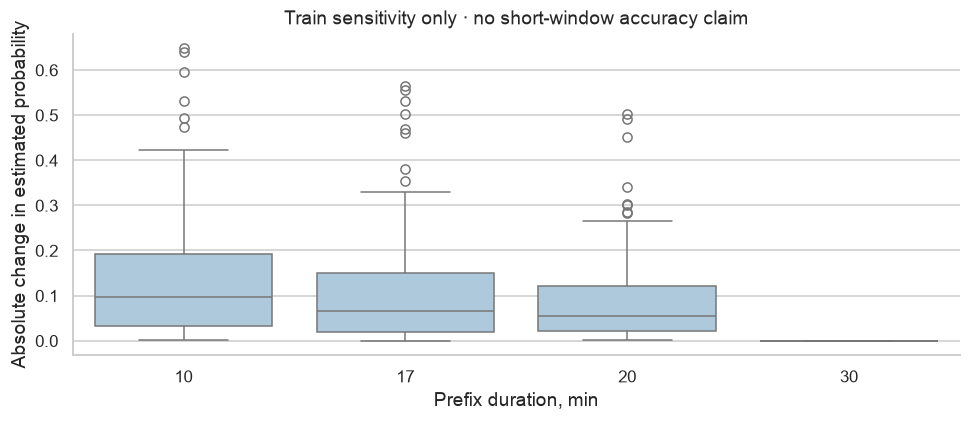

In [17]:
drift=pd.read_parquet(OUT/'duration_probability_drift.parquet')
display(drift.groupby('prefix_min').absolute_change.agg(['count','median','mean','max']).round(4))
fig,ax=plt.subplots(figsize=(9,4))
sns.boxplot(data=drift,x='prefix_min',y='absolute_change',color='#a6cbe3',ax=ax)
ax.set(xlabel='Prefix duration, min',ylabel='Absolute change in estimated probability',title='Train sensitivity only · no short-window accuracy claim')
fig.tight_layout();save_show('11_duration_probability_drift.png')


## Takeaways

- Проверено сохранение моделей/преобразований и границ независимости. 300-деревные точки сетки действительно совпадают с префиксами 700-деревных моделей при проверенных настройках.
- Все модели оценены на одной закрытой test-части после выбора решений. Модели/профили не перестраиваются по ошибкам этого test.
- Устойчивость к отсутствующим измерениям и качество на трудных записях видны отдельно от среднего score. Отсутствие обязательного поля требует явного маршрута/отказа, а не заполнения «нормой».
- У расширенного CatBoost пропущены 527 abnormal-записей из 2219. Даже хорошее среднее ранжирование AP 0.856 не устраняет эту ошибку при пороге 0.5. Отдельного доказанно безопасного клинического порога в работе нет.
- Прототип воспроизводит экспертный класс JNU. Нет независимой российской дородовой валидации, отдельного suspect/pathologic target, подтверждённого vendor bridge и валидированного риска асфиксии. Эти границы не устраняются большим Grid Search или узким внутренним CI.
